In [340]:
import scipy as sp
import numpy as np

In [341]:
2*np.sqrt(3)

np.float64(3.4641016151377544)

In [342]:
M = 1
L = 2*M
E = 1
y0 = np.array([5.0, 0.0, 0.0, 0.0])
t_int = (0, 1000)

def system(tau, y):
    print(y)
    r, rdot, t, phi = y
    return np.array([
        -M / r**2 + L**2 / r**3 - 3 * M * L**2 / r**4,
        rdot,
        E / (1-2*M/r),
        L / r**2
    ])



def stop_on_horizon(tau, y):
    return y[0] - (2.0+1e-8)*M


stop_on_horizon.terminal = True
stop_on_horizon.direction = -1  # stop when r decreases through r_stop (infall)


In [343]:
sol = sp.integrate.solve_ivp(
    system, t_int, y0,
    events=stop_on_horizon,
    dense_output=True,
    rtol=1e-10,
    atol=1e-12
)

[5. 0. 0. 0.]
[4.99999837e+00 0.00000000e+00 9.96856274e-05 4.78491011e-06]
[4.99999106e+00 0.00000000e+00 5.47791196e-04 2.62939774e-05]
[4.99998659e+00 0.00000000e+00 8.21687529e-04 3.94410719e-05]
[4.99996424e+00 0.00000000e+00 2.19117001e-03 1.05176662e-04]
[4.99996027e+00 0.00000000e+00 2.43463399e-03 1.16863051e-04]
[4.99995530e+00 0.00000000e+00 2.73896414e-03 1.31471062e-04]
[4.99995530e+00 0.00000000e+00 2.73896414e-03 1.31471062e-04]
[4.99986590e+00 0.00000000e+00 8.21690875e-03 3.94415538e-04]
[4.99982119e+00 0.00000000e+00 1.09559545e-02 5.25898354e-04]
[4.99959767e+00 0.00000000e+00 2.46512651e-02 1.18332420e-03]
[4.99955793e+00 0.00000000e+00 2.70860297e-02 1.30020607e-03]
[4.99950825e+00 0.00000000e+00 3.01295036e-02 1.44631101e-03]
[4.99950825e+00 0.00000000e+00 3.01295036e-02 1.44631100e-03]
[4.99861406e+00 0.00000000e+00 8.49122155e-02 4.07622602e-03]
[4.99816656 0.         0.11231092 0.00539224]
[4.99592862 0.         0.24931271 0.01197351]
[4.99553052 0.         0.2

In [344]:
sol.t

array([0.00000000e+00, 1.64337359e-03, 1.80771095e-02, 1.82414468e-01,
       1.43590060e+00, 3.14446700e+00, 5.06332249e+00, 7.08820008e+00,
       9.16002230e+00, 1.12405617e+01, 1.33034054e+01, 1.53297000e+01,
       1.73058136e+01, 1.92219062e+01, 2.10709855e+01, 2.28482468e+01,
       2.45505910e+01, 2.61762613e+01, 2.77245629e+01, 2.91956414e+01,
       3.05903070e+01, 3.19098916e+01, 3.31561327e+01, 3.43310786e+01,
       3.54370092e+01, 3.64763718e+01, 3.74517266e+01, 3.83657014e+01,
       3.92209535e+01, 4.00201374e+01, 4.07658757e+01, 4.14607345e+01,
       4.21071989e+01, 4.27076507e+01, 4.32643458e+01, 4.37793915e+01,
       4.42547286e+01, 4.46921205e+01, 4.50931652e+01, 4.54593408e+01,
       4.57920977e+01, 4.60628886e+01, 4.63336795e+01, 4.65535462e+01,
       4.67734129e+01, 4.69509406e+01, 4.71284684e+01, 4.72718467e+01,
       4.74152249e+01, 4.75313791e+01, 4.76475333e+01, 4.77419886e+01,
       4.78364440e+01, 4.79135159e+01, 4.79905879e+01, 4.80536363e+01,
      

In [345]:
traj_sol_fn = sol.sol
t_final = sol.t[-1]
data_sol = traj_sol_fn(np.linspace(t_int[0], t_final, 1000))

In [346]:
r, rdot, t, phi = sol.y

In [347]:
def convert_sol_to_cart(r_list, phi_list):
    return r_list * np.cos(phi_list), r_list * np.sin(phi_list)

In [348]:
x,y = convert_sol_to_cart(data_sol[0], data_sol[-1])

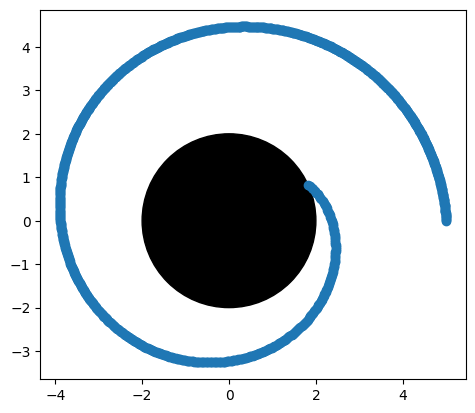

In [349]:
from matplotlib import pyplot as plt
from matplotlib.patches import Circle
fig, ax = plt.subplots()
ax.set_aspect("equal")  # so the circle looks round, not an ellipse
c = Circle((0.0, 0.0), radius=2, fill=True, edgecolor="k", linewidth=1, facecolor="k")
ax.add_patch(c)
ax.autoscale_view()
ax.scatter(x,y)
#ax.set_xlim(-6,6)
#ax.set_ylim(-6,6)
plt.show()